### Capstone Part 4: Megan and Arianna

*I realized that NGC 3351 and M95 are the same thing, so I'm getting rid of NGC 3351 and just keeping M95. That means we're now analyzing 7 galaxies*

In [1]:
#import 
from astropy.stats import sigma_clipped_stats
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile
import astropy.units as u
from scipy import stats

from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib import pyplot as plt
import numpy as np
from matplotlib import colors


from astropy.nddata import CCDData
#from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

In [2]:
def imdisplay(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    fig,ax = plt.subplots(figsize=(6,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(v1,v2)
    if (logscale):
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        
    cbar = fig.colorbar(im, ax=ax, fraction=0.04)
    cbar.ax.set_ylabel('counts')
    return fig,ax

In [3]:
def imdisplay2(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display two copies of an image side-by-side
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    #this makes two horizontal figures 
    fig,axs = plt.subplots(1,2,figsize=(12,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(f"v1 = {v1:5.2f}, v2 = {v2:5.2f}")
    if (logscale):
        #plot the two figures side by side
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')

    #plot colorbars for each subplot
    cbar0 = fig.colorbar(im0, ax=axs[0], fraction=0.04)
    cbar0.ax.set_ylabel('counts')
    cbar1 = fig.colorbar(im1, ax=axs[1], fraction=0.04)
    cbar1.ax.set_ylabel('counts')
    return fig,axs

### Estimate and Subtract Background

In [4]:
def background_meas(imname,data,header,fig,ax,corners,bkg_size=5):
    #need to find ways to select regions of pixels in image
    fig,ax = imdisplay(data,v1perc=60,v2perc=99,logscale=True)

    plt.title(imname)

    #print out the x and y-dimension of the image using the header keywords
    print('image xdim = ', header['NAXIS1'], '; image ydim = ',header['NAXIS2'])
    #the length of each background box size
    #bkg_size = 200

    #make an array whose elements are the different data sections.
    reg = np.array([])


    #specify the different regions.  Each will be appended to the reg array.  the reg array is therefore 3 dimensional.  
    #the first dimension is for each region.  Each of those dimensions contains a 2D array that holds the image section.
    reg = np.append(reg, data[corners[0][0]:bkg_size-1, corners[0][1]:bkg_size-1])    #lower left corner
    reg = np.append(reg, data[corners[1][0]:bkg_size-1, corners[1][1]:])    #upper left corner
    reg = np.append(reg, data[corners[2][0]:, corners[2][1]:])    #upper right corner
    reg = np.append(reg, data[corners[3][0]:, corners[3][1]:bkg_size-1])   #lower right corner

    #print the median and mode of all the pixels. 
    bkgmode =stats.mode(reg,keepdims=False)[0]
    bkgmed = np.median(reg)
    print('mode = ',bkgmode)
    print('median = ',bkgmed)

    #Overlay rectangles with the background region indicated
    rectlist = []
    #loop through all images 
    for corn in corners:
        rect = plt.Rectangle((corn),bkg_size, bkg_size,linewidth=2,angle=0.0)
        rectlist.append(rect)
        pc = PatchCollection(rectlist,linewidth=1,edgecolor='r',facecolor='none')
        ax.add_collection(pc)
        
    return bkgmode,bkgmed

In [5]:
#a routine to plot the images with the background measurement corners shown in red
def bkgregplot(data,header,imname, bkgdim, fig, ax):
    #define lower-left corners of each region
    corners = []
    corners.append([0,0])
    corners.append([0,header['NAXIS2']-bkgdim])
    corners.append([header['NAXIS1']-bkgdim, header['NAXIS2']-bkgdim])
    corners.append([header['NAXIS1']-bkgdim,0])

    #run the background_meas code to measure the background and plot the background regions
    bkgmode,bkgmed = background_meas(imname, data, header, fig, ax, 
                                                       corners,bkg_size=bkgdim)
    return bkgmode, bkgmed

In [6]:
#initialize dictionaries that contains names of images and headers
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}

#statistics of background
bkgmode = {}
bkgmed = {}

#### M95

In [34]:
datadir = '/home/m529w976/ASTR596/Capstone_data/M95'
os.chdir(datadir)

1.510783913545317e-05 0.26516399472951874
0.0030309517867863154 0.26516399472951874
image xdim =  3600 ; image ydim =  3600
mode =  0.0
median =  0.0006388708716258407
0.0008275102009065449 1.5957960891370266


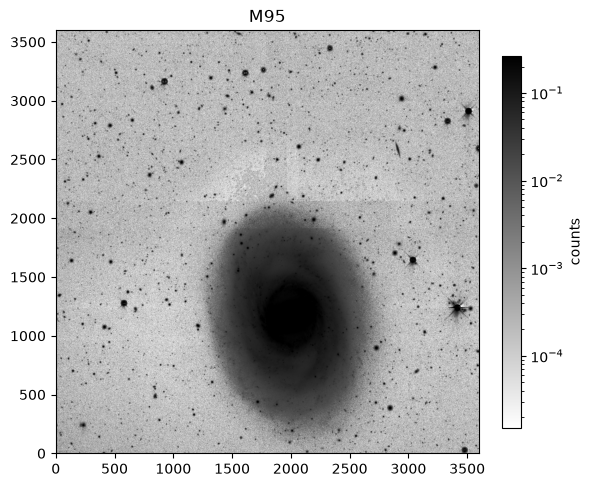

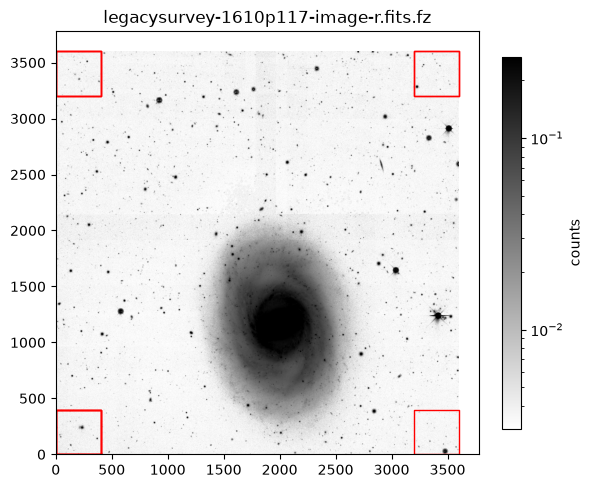

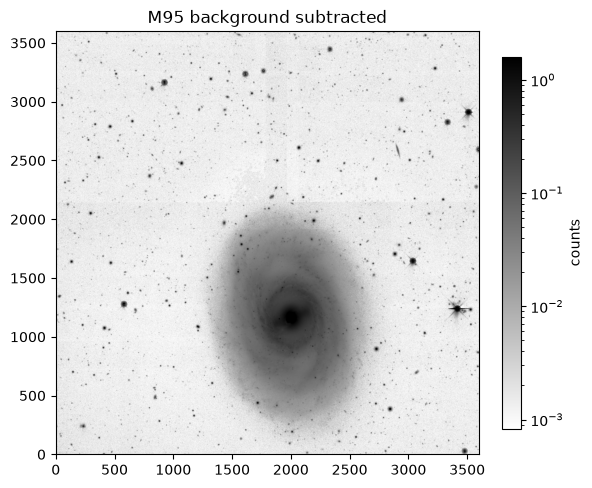

In [35]:
imname = 'legacysurvey-1610p117-image-r.fits.fz'
#fig,ax = plt.subplots(figsize=(6,6))
data,header = fits.getdata(imname, header=True)
fig,ax = imdisplay(data,v1perc=40,v2perc=99,logscale=True)
plt.title('M95')
#---
#initialize dictionaries that contains names of images and headers
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}

#statistics of background
bkgmode = {}
bkgmed = {}

galname = 'M95'
imname[galname] = 'legacysurvey-1610p117-image-r.fits.fz'
#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 400

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)
#---
data_bsub = {}
imname_bsub = {}

galname = 'M95'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]

#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=50,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace("image-r.fits.fz","bsub-image-r.fits.fz")

# save the background_subtracted image to a file
#fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

#### NGC 1087

In [42]:
datadir = '/home/m529w976/ASTR596/Capstone_data/NGC1087'
os.chdir(datadir)

0.0006449942593462765 10.000004768371582
0.0014032020699232817 0.18426934093236919
image xdim =  3600 ; image ydim =  3600
mode =  -0.002307069720700383
median =  0.00020427553681656718
0.00044071872252970934 9.999800492834765


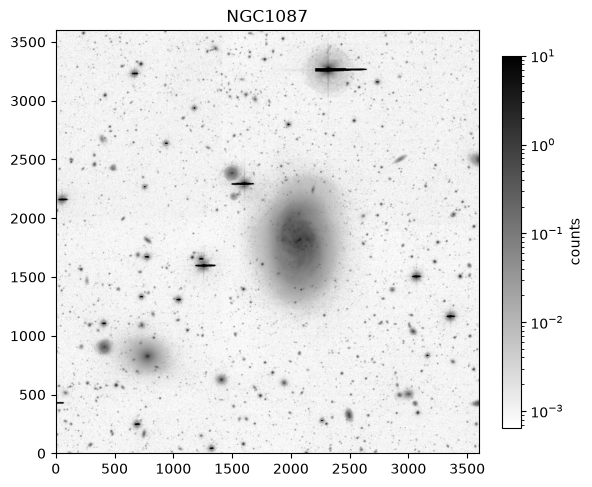

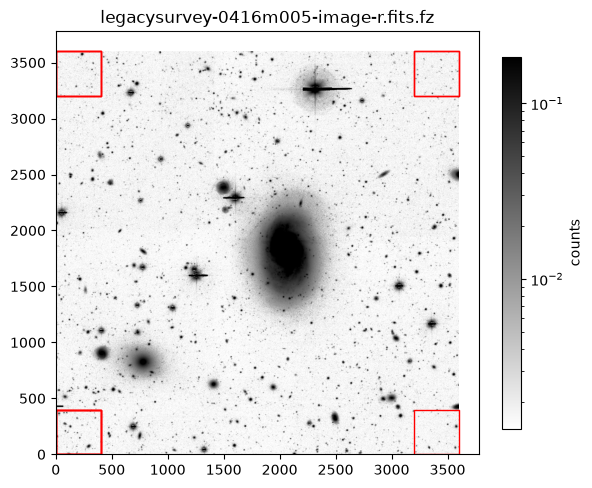

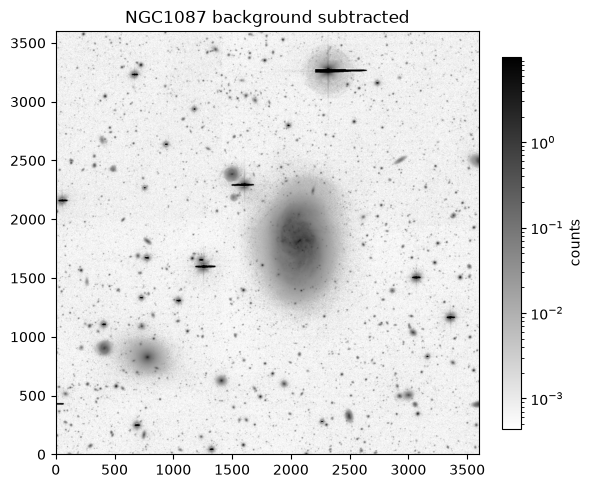

In [43]:
imname = 'legacysurvey-0416m005-image-r.fits.fz'
#fig,ax = plt.subplots(figsize=(6,6))
data,header = fits.getdata(imname, header=True)
fig,ax = imdisplay(data,v1perc=50,v2perc=99.9,logscale=True)
plt.title('NGC1087')
#---
#initialize dictionaries that contains names of images and headers
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}

#statistics of background
bkgmode = {}
bkgmed = {}

galname = 'NGC1087'
imname[galname] = 'legacysurvey-0416m005-image-r.fits.fz'
#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 400

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)
#---
data_bsub = {}
imname_bsub = {}

galname = 'NGC1087'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]

#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=50,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace("image-r.fits.fz","bsub-image-r.fits.fz")

# save the background_subtracted image to a file
#fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

#### NGC 1385

In [48]:
datadir = '/home/m529w976/ASTR596/Capstone_data/NGC1385'
os.chdir(datadir)

0.0005111508071422577 1.1031053029301123
0.0011915585957467554 0.12360173180699321
image xdim =  3600 ; image ydim =  3600
mode =  0.0
median =  0.00031557196052744985
0.00019557884661480784 1.1027897309695849


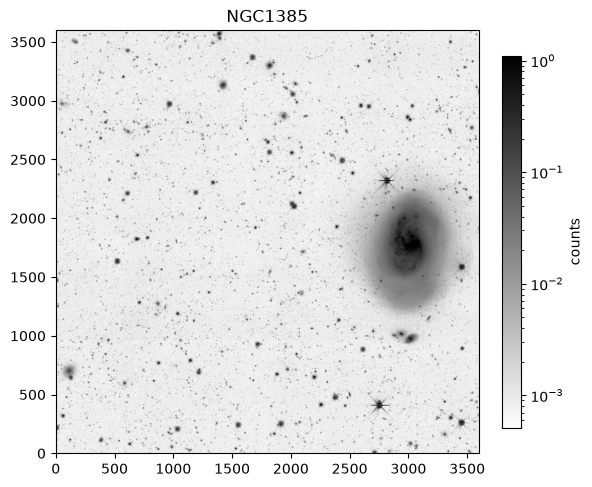

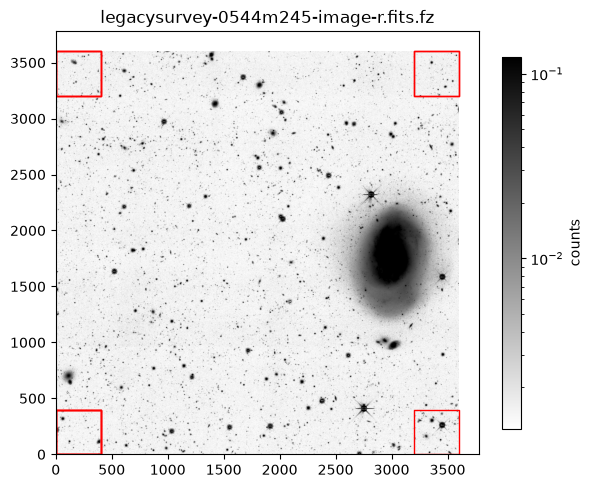

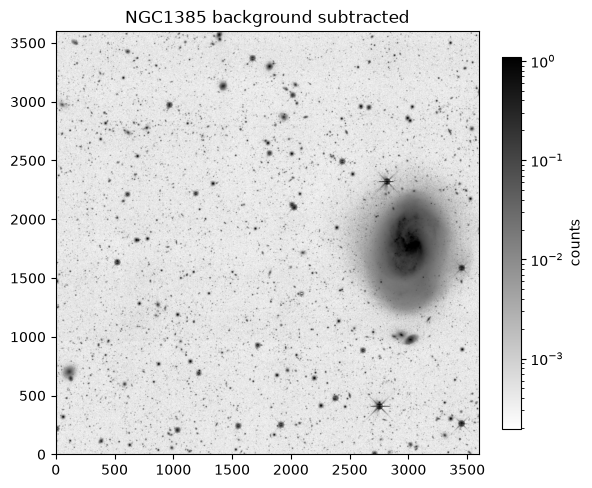

In [49]:
imname = 'legacysurvey-0544m245-image-r.fits.fz'
#fig,ax = plt.subplots(figsize=(6,6))
data,header = fits.getdata(imname, header=True)
fig,ax = imdisplay(data,v1perc=50,v2perc=99.9,logscale=True)
plt.title('NGC1385')
#---
#initialize dictionaries that contains names of images and headers
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}

#statistics of background
bkgmode = {}
bkgmed = {}

galname = 'NGC1385'
imname[galname] = 'legacysurvey-0544m245-image-r.fits.fz'
#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 400

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)
#---
data_bsub = {}
imname_bsub = {}

galname = 'NGC1385'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]

#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=50,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace("image-r.fits.fz","bsub-image-r.fits.fz")

# save the background_subtracted image to a file
#fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

#### NGC 3054

In [53]:
datadir = '/home/m529w976/ASTR596/Capstone_data/NGC3054'
os.chdir(datadir)

0.0007682601572014391 2.065298566104932
0.0021352032199501974 0.14186012297868705
image xdim =  3600 ; image ydim =  3600
mode =  0.0
median =  0.000417549250414595
0.00035071090678684413 2.0648810168545175


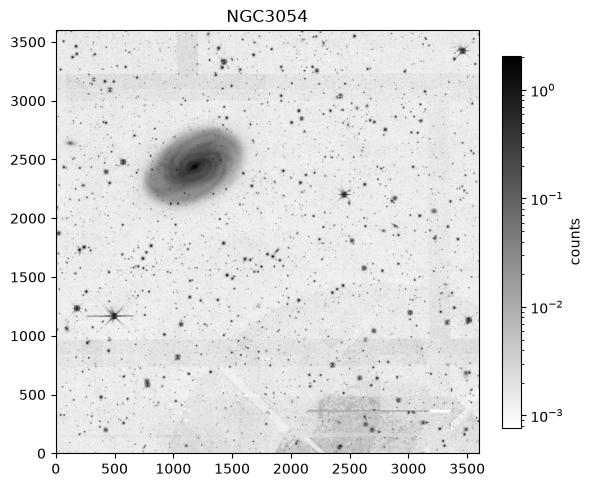

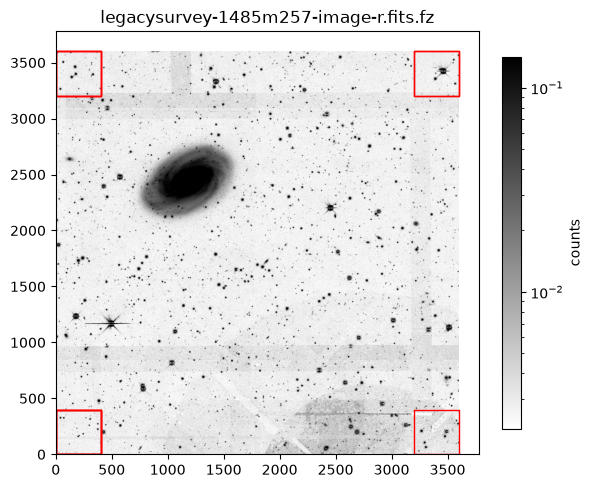

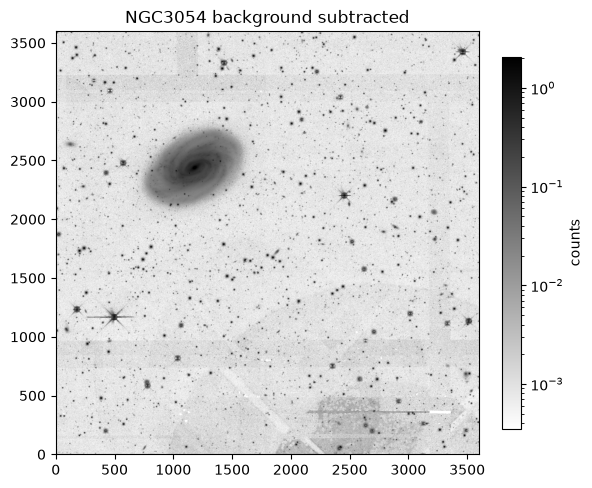

In [54]:
imname = 'legacysurvey-1485m257-image-r.fits.fz'
#fig,ax = plt.subplots(figsize=(6,6))
data,header = fits.getdata(imname, header=True)
fig,ax = imdisplay(data,v1perc=50,v2perc=99.9,logscale=True)
plt.title('NGC3054')
#---
#initialize dictionaries that contains names of images and headers
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}

#statistics of background
bkgmode = {}
bkgmed = {}

galname = 'NGC3054'
imname[galname] = 'legacysurvey-1485m257-image-r.fits.fz'
#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 400

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)
#---
data_bsub = {}
imname_bsub = {}

galname = 'NGC3054'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]

#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=50,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace("image-r.fits.fz","bsub-image-r.fits.fz")

# save the background_subtracted image to a file
#fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

#### NGC 3596

In [59]:
datadir = '/home/m529w976/ASTR596/Capstone_data/NGC3596'
os.chdir(datadir)

0.0006628874689340591 0.5092331674696036
0.0022148906718939534 0.09231639228761172
image xdim =  3600 ; image ydim =  3600
mode =  -0.007364214397966862
median =  0.00020172051154077053
0.0004611669573932886 0.5090314469580628


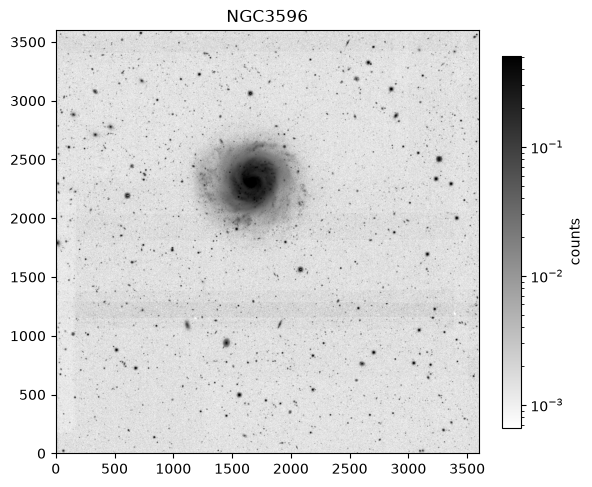

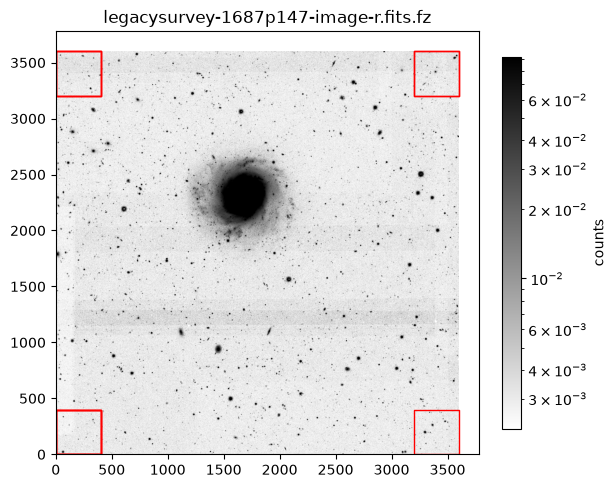

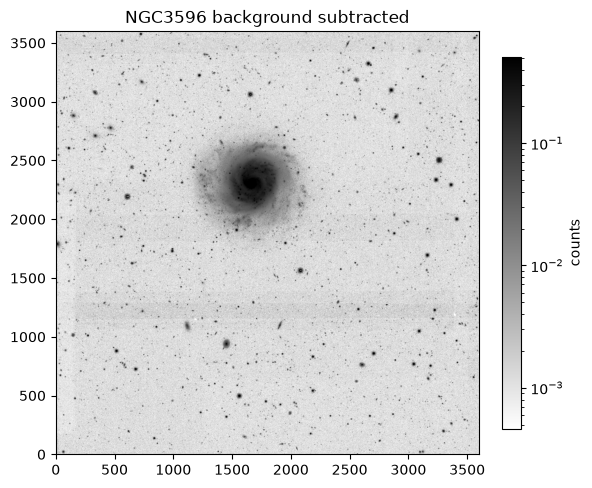

In [60]:
imname = 'legacysurvey-1687p147-image-r.fits.fz'
#fig,ax = plt.subplots(figsize=(6,6))
data,header = fits.getdata(imname, header=True)
fig,ax = imdisplay(data,v1perc=50,v2perc=99.9,logscale=True)
plt.title('NGC3596')
#---
#initialize dictionaries that contains names of images and headers
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}

#statistics of background
bkgmode = {}
bkgmed = {}

galname = 'NGC3596'
imname[galname] = 'legacysurvey-1687p147-image-r.fits.fz'
#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 400

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)
#---
data_bsub = {}
imname_bsub = {}

galname = 'NGC3596'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]

#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=50,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace("image-r.fits.fz","bsub-image-r.fits.fz")

# save the background_subtracted image to a file
#fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

#### NGC 3672

In [63]:
datadir = '/home/m529w976/ASTR596/Capstone_data/NGC3672'
os.chdir(datadir)

0.0004457986360648647 0.8631675238014465
0.0015790548175573327 0.12480948023498027
image xdim =  3600 ; image ydim =  3600
mode =  -0.004108164459466934
median =  0.0002590087824501097
0.00018678985361475497 0.8629085150189963


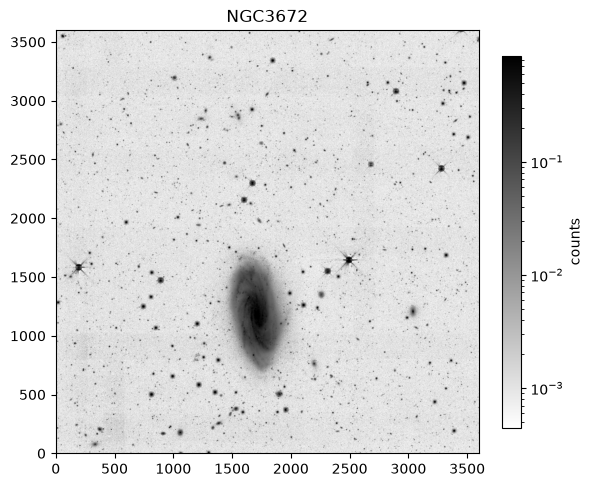

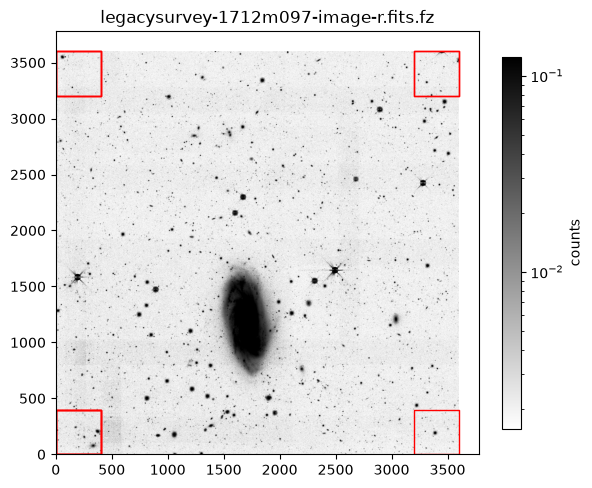

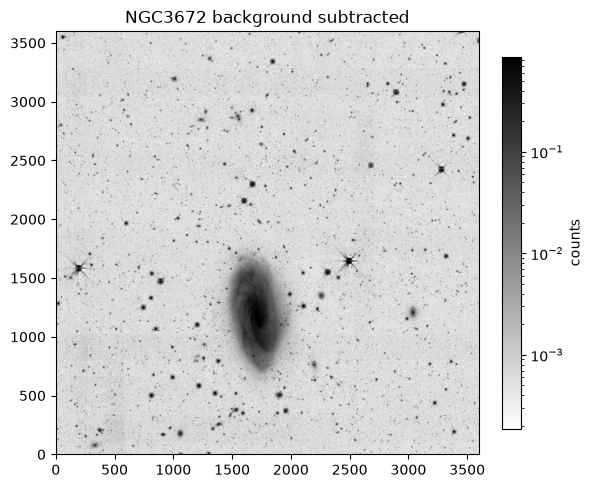

In [64]:
imname = 'legacysurvey-1712m097-image-r.fits.fz'
#fig,ax = plt.subplots(figsize=(6,6))
data,header = fits.getdata(imname, header=True)
fig,ax = imdisplay(data,v1perc=50,v2perc=99.9,logscale=True)
plt.title('NGC3672')
#---
#initialize dictionaries that contains names of images and headers
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}

#statistics of background
bkgmode = {}
bkgmed = {}

galname = 'NGC3672'
imname[galname] = 'legacysurvey-1712m097-image-r.fits.fz'
#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 400

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)
#---
data_bsub = {}
imname_bsub = {}

galname = 'NGC3672'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]

#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=50,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace("image-r.fits.fz","bsub-image-r.fits.fz")

# save the background_subtracted image to a file
#fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

#### NGC 4252

In [68]:
datadir = '/home/m529w976/ASTR596/Capstone_data/NGC4252'
os.chdir(datadir)

0.0012241688091307878 10.000000953674316
0.002531007211655378 0.3617388790845867
image xdim =  3600 ; image ydim =  3600
mode =  -0.005266719032078981
median =  0.00046900552115403116
0.0007551632879767567 9.999531948153162


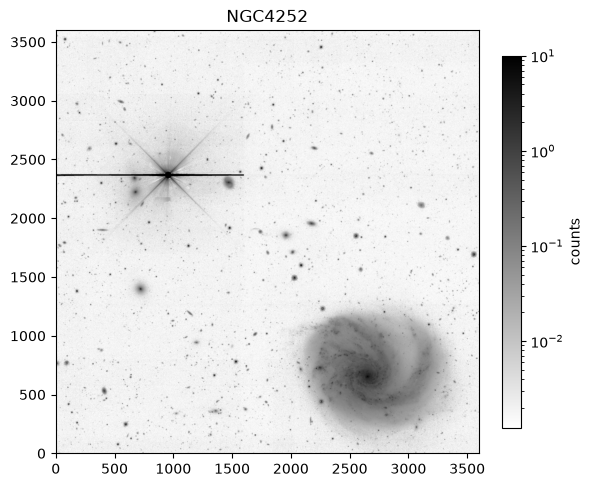

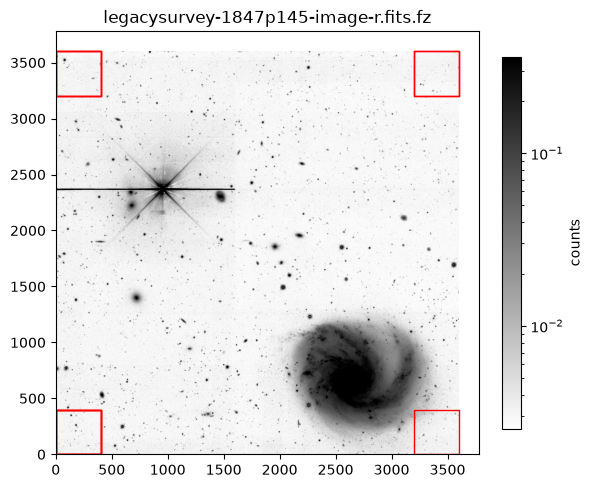

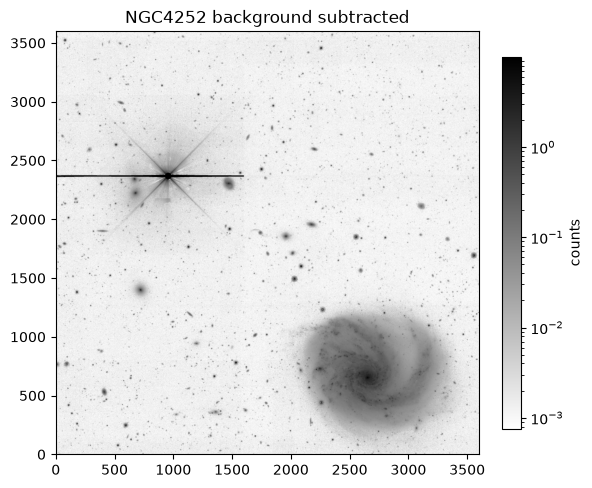

In [69]:
imname = 'legacysurvey-1847p145-image-r.fits.fz'
#fig,ax = plt.subplots(figsize=(6,6))
data,header = fits.getdata(imname, header=True)
fig,ax = imdisplay(data,v1perc=50,v2perc=99.9,logscale=True)
plt.title('NGC4252')
#---
#initialize dictionaries that contains names of images and headers
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}

#statistics of background
bkgmode = {}
bkgmed = {}

galname = 'NGC4252'
imname[galname] = 'legacysurvey-1847p145-image-r.fits.fz'
#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 400

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)
#---
data_bsub = {}
imname_bsub = {}

galname = 'NGC4252'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]

#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=50,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace("image-r.fits.fz","bsub-image-r.fits.fz")

# save the background_subtracted image to a file
#fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

### Ellipse Parameters

#### M95

In [36]:
#initialize the dictionary containing the intial parameters for the ellipse fitting
initparams = {}
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'M95'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 2005
initparams[galname]['ycen'] = 1160
#semi-major axis [pixels]
initparams[galname]['sma'] = 297
#semin-minor axis [pixels]
initparams[galname]['smina'] = 212
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 280.0

#### NGC 1087

In [44]:
#initialize the dictionary containing the intial parameters for the ellipse fitting
initparams = {}
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC1087'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 2064
initparams[galname]['ycen'] = 1788
#semi-major axis [pixels]
initparams[galname]['sma'] = 151
#semin-minor axis [pixels]
initparams[galname]['smina'] = 91
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 95.0

#### NGC 1385

In [50]:
#initialize the dictionary containing the intial parameters for the ellipse fitting
initparams = {}
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC1385'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 3026
initparams[galname]['ycen'] = 1794
#semi-major axis [pixels]
initparams[galname]['sma'] = 139
#semin-minor axis [pixels]
initparams[galname]['smina'] = 90
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 80.0

#### NGC 3054

In [55]:
#initialize the dictionary containing the intial parameters for the ellipse fitting
initparams = {}
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC3054'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 1177
initparams[galname]['ycen'] = 2438
#semi-major axis [pixels]
initparams[galname]['sma'] = 184
#semin-minor axis [pixels]
initparams[galname]['smina'] = 104
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 30.0

#### NGC 3596

In [61]:
#initialize the dictionary containing the intial parameters for the ellipse fitting
initparams = {}
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC3596'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 1674
initparams[galname]['ycen'] = 2305
#semi-major axis [pixels]
initparams[galname]['sma'] = 98
#semin-minor axis [pixels]
initparams[galname]['smina'] = 82
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 45.0

#### NGC 3672

In [65]:
#initialize the dictionary containing the intial parameters for the ellipse fitting
initparams = {}
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC3672'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 1709
initparams[galname]['ycen'] = 1180
#semi-major axis [pixels]
initparams[galname]['sma'] = 182
#semin-minor axis [pixels]
initparams[galname]['smina'] = 98
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 96.0

#### NGC 4252

In [70]:
#initialize the dictionary containing the intial parameters for the ellipse fitting
initparams = {}
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC4252'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 2653
initparams[galname]['ycen'] = 659
#semi-major axis [pixels]
initparams[galname]['sma'] = 195
#semin-minor axis [pixels]
initparams[galname]['smina'] = 178
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 0.0

### Isophotes and Radial Profiles

In [45]:
from photutils.isophote import EllipseGeometry
from photutils.aperture import EllipticalAperture

#define an empty dictionary that will contain the EllipseGeometry instance
geometry = {}

#### M95

297 0.2861952861952862
0.0008275102009065449 9.999384970986284


Text(0.5, 1.0, 'M95')

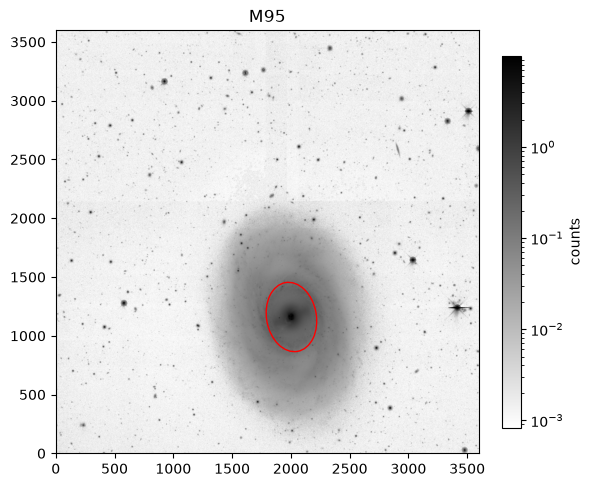

In [39]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'M95'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=50,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

#### NGC 1087

151 0.3973509933774835
0.00044071872252970934 9.999841500830371


Text(0.5, 1.0, 'NGC1087')

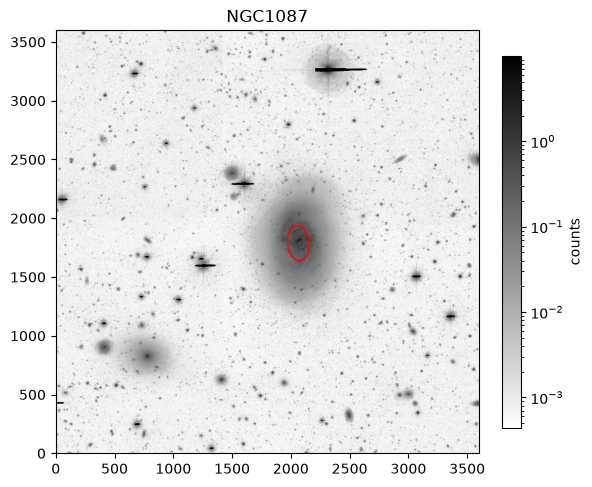

In [46]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC1087'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=50,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

#### NGC 1385

139 0.3525179856115108
0.00019557884661480784 9.999708269897383


Text(0.5, 1.0, 'NGC1385')

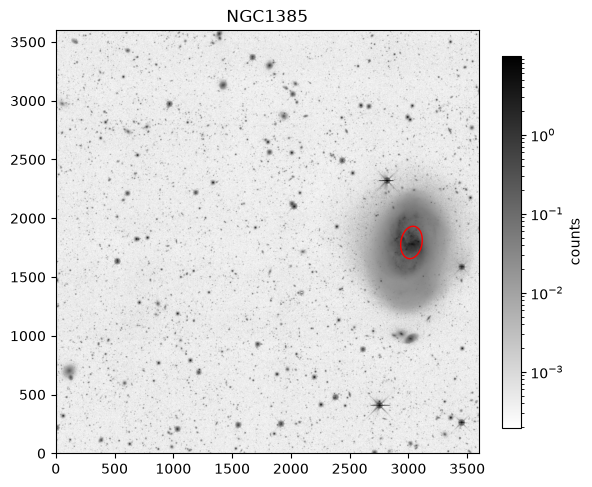

In [51]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC1385'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=50,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

#### NGC 3054

184 0.4347826086956522
0.00035071090678684413 9.99962631976814


Text(0.5, 1.0, 'NGC3054')

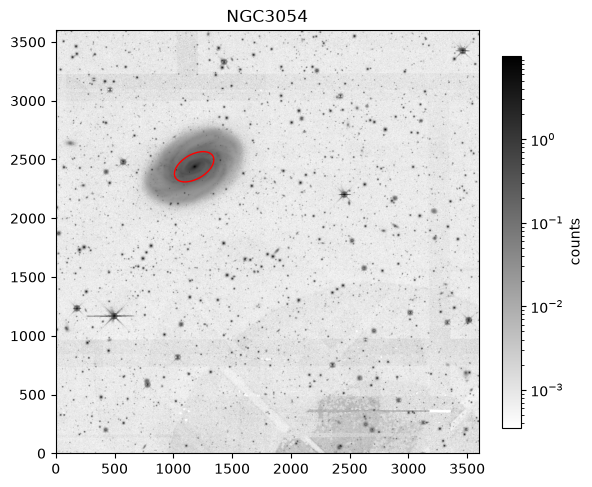

In [56]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC3054'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=50,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

#### NGC 3596

98 0.16326530612244894
0.0004611669573932886 4.90311112495368


Text(0.5, 1.0, 'NGC3596')

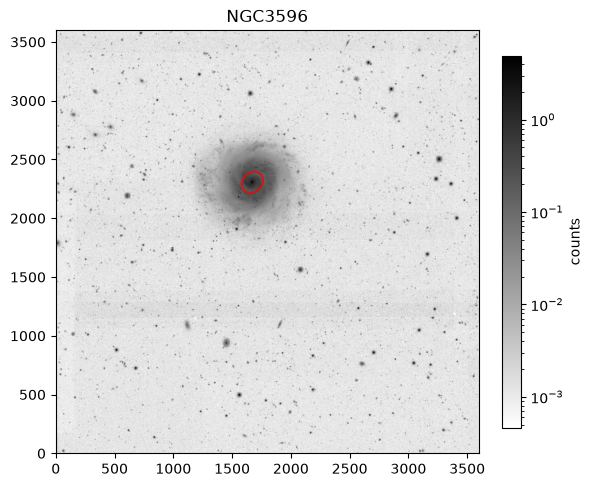

In [62]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC3596'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=50,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

#### NGC 3672

182 0.46153846153846156
0.00018678985361475497 9.999783906561788


Text(0.5, 1.0, 'NGC3672')

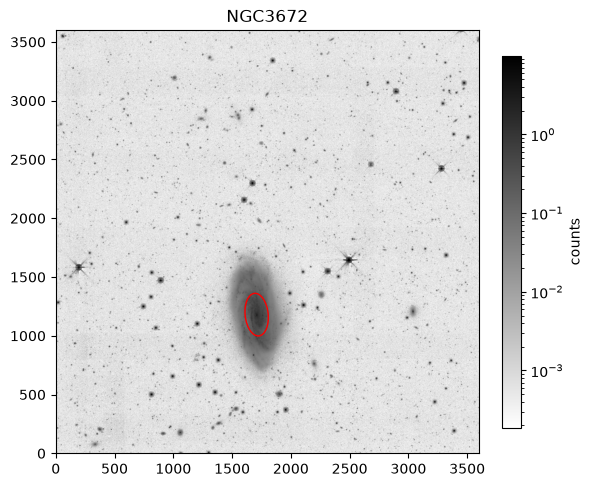

In [66]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC3672'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=50,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

#### NGC 4252

195 0.0871794871794872
0.0007551632879767567 9.999578678194666


Text(0.5, 1.0, 'NGC4252')

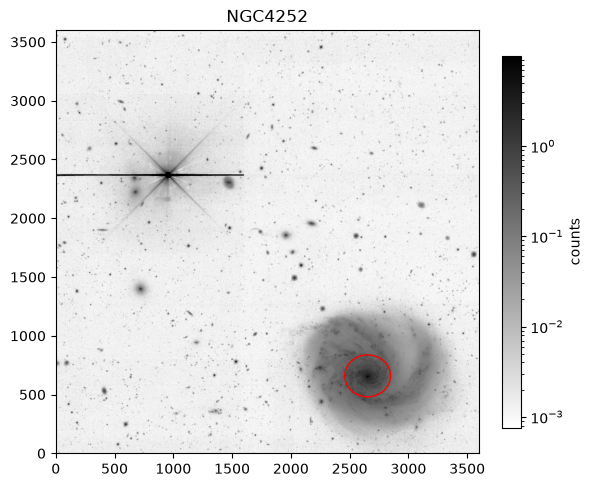

In [71]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC4252'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=50,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

In [72]:
def plotellipse(isolist):
    plt.figure(figsize=(8, 8))
    plt.subplots_adjust(hspace=0.35, wspace=0.35)

    #plot the semi-major axis vs. the ellipticity
    plt.subplot(2, 2, 1)
    plt.errorbar(isolist.sma, isolist.eps, yerr=isolist.ellip_err,
                 fmt='o', markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('Ellipticity')

    #plot the semi-major axis vs. the PA
    plt.subplot(2, 2, 2)
    plt.errorbar(isolist.sma, isolist.pa / np.pi * 180.0,
                 yerr=isolist.pa_err / np.pi * 80.0, fmt='o', markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('PA (deg)')

    #plot the semi-major axis vs. the x center of that ellipse
    plt.subplot(2, 2, 3)
    plt.errorbar(isolist.sma, isolist.x0, yerr=isolist.x0_err, fmt='o',
                 markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('x0')

    #plot the semi-major axis vs. the y center of that ellipse
    plt.subplot(2, 2, 4)
    plt.errorbar(isolist.sma, isolist.y0, yerr=isolist.y0_err, fmt='o',
                 markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('y0')

In [73]:
#this subroutine will plot every other isophote on top of the galaxy image
def plotaper(galname, image, isophote_list,vminperc=45,vmaxperc=99.99):

    #plot image
    #plt.subplots(figsize=(6,6))
    fig,ax = imdisplay2(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)

    #Loop through all apertures starting at the first (not zero) and going to every other aperture
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((isophote_list.x0[i], isophote_list.y0[i]), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-isophote_list.eps[i]), isophote_list.pa[i])
    
        #overplot apertures
        aperiter.plot(ax=ax[0],color='red')

    #plot the isophotes that have parameters fixed to the median parameters of all but the "apmin" inner isphotes
    #compute median isophote parameters ignoring inner isophotes.  This is because the inner isophotes all tend to be rather circular
    apmin = 20   #the minimum inner isophote in terms of isophote number.
    xcenav = np.median(isophote_list.x0[apmin:])
    ycenav = np.median(isophote_list.y0[apmin:])
    epsav = np.median(isophote_list.eps[apmin:])
    paav = np.median(isophote_list.pa[apmin:])
    
    #fig,ax = imdisplay(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((xcenav, ycenav), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-epsav), paav)
    
        #overplot apertures
        aperiter.plot(ax=ax[1],color='blue')

    ax[0].set_title(galname + ' free ellipse parameters')
    ax[1].set_title(galname + ' fixed ellipse parameters')

    return xcenav, ycenav, epsav, paav

In [74]:
from photutils.isophote import Ellipse

#initialize dictionary for ellipse fitting
ellipse = {}
isolist = {}

In [75]:
xcenav = {}
ycenav = {}
epsav = {}
paav = {}

#### M59

In [77]:
#this will do the fitting of the isophotes by making an instance of the Ellipse class
#It then fits the data using the initial guesses we computed above
galname = 'M95'
ellipse[galname] = Ellipse(data_bsub[galname], geometry[galname])
isolist[galname] = ellipse[galname].fit_image()

#this puts the output into a table containing every ellipse.   
#You can comment this first line out if you don't want it always to print out.
#print(isolist[galname].eps)

#make a set of plots that show some attributes of every ellipse.
plotellipse(isolist[galname])
#save the shape values of the average ellipse.  We will need this later for aperture photometry
xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, data_bsub[galname],isolist[galname])

KeyError: 'M95'